# From Bootstrap to Asymptotic Inference

## Introduction
- We're going to show how you can approximate non-parametric bootstrap inference by using the Normal distribution
- Our running example will be **hedonic pricing**: predicting the value of housing based on its amenities (square feet, bathrooms, total rooms, area, age)

## 1. Sampling the Sampling Distribution
- You have covered OLS/linear regression in ML1, so we can play with it here
- We'll use the Ames housing price data, and run a simple regression:
$$
\begin{alignat*}{2}
\widehat{\log(\text{price})}_i &=& \text{const} + \beta_{\text{area}} \log(\text{area}_i) + \beta_{\text{age}} \log(\text{age}_i) \\
&&+ \sum_k \beta_{\text{rooms}= k} \text{rooms}_{i, k} + \sum_k \beta_{\text{quality}= k} \text{quality}_{i, k}
+ \sum_k \beta_{\text{baths} = k} \text{baths}_{i, k} 
\end{alignat*}
$$
- The second line are all one-hot encoded/dummy, and the first like are continuous/numeric variables
- We'll resample the data $(X,y)$, running this regression thousands of times and caching the coefficients

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd 
import seaborn as sns 

from scipy.stats import norm

df = pd.read_csv('./data/ames_prices.csv')
df.head()

,Order,PID,area,price,MS.SubClass,MS.Zoning,Lot.Frontage,Lot.Area,Street,Alley,...,Screen.Porch,Pool.Area,Pool.QC,Fence,Misc.Feature,Misc.Val,Mo.Sold,Yr.Sold,Sale.Type,Sale.Condition
0,1,526301100,1656,215000,20,RL,141.0,31770,Pave,NaN,...,0,0,NaN,NaN,NaN,0,5,2010,WD,Normal
1,2,526350040,896,105000,20,RH,80.0,11622,Pave,NaN,...,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal
2,3,526351010,1329,172000,20,RL,81.0,14267,Pave,NaN,...,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal
3,4,526353030,2110,244000,20,RL,93.0,11160,Pave,NaN,...,0,0,NaN,NaN,NaN,0,4,2010,WD,Normal
4,5,527105010,1629,189900,60,RL,74.0,13830,Pave,NaN,...,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal


<Axes: xlabel='price', ylabel='Density'>

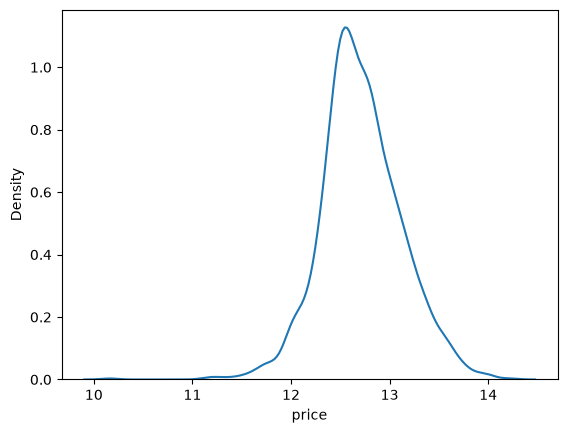

In [2]:
sns.kdeplot( np.arcsinh(df['price']) )

In [3]:
df = df.drop(['Pool.QC', 'Misc.Feature', 'Pool.QC','Alley', 'Fence', 
              'Mas.Vnr.Type', 'Fireplace.Qu',
         'Lot.Frontage', ], axis =1)
df.head()
df['age'] = df['Year.Built'].max() - df['Year.Built']
df['Garage.Type'] = df['Garage.Type'].fillna('None')

In [4]:
df.columns

Index(['Order', 'PID', 'area', 'price', 'MS.SubClass', 'MS.Zoning', 'Lot.Area',
       'Street', 'Lot.Shape', 'Land.Contour', 'Utilities', 'Lot.Config',
       'Land.Slope', 'Neighborhood', 'Condition.1', 'Condition.2', 'Bldg.Type',
       'House.Style', 'Overall.Qual', 'Overall.Cond', 'Year.Built',
       'Year.Remod.Add', 'Roof.Style', 'Roof.Matl', 'Exterior.1st',
       'Exterior.2nd', 'Mas.Vnr.Area', 'Exter.Qual', 'Exter.Cond',
       'Foundation', 'Bsmt.Qual', 'Bsmt.Cond', 'Bsmt.Exposure',
       'BsmtFin.Type.1', 'BsmtFin.SF.1', 'BsmtFin.Type.2', 'BsmtFin.SF.2',
       'Bsmt.Unf.SF', 'Total.Bsmt.SF', 'Heating', 'Heating.QC', 'Central.Air',
       'Electrical', 'X1st.Flr.SF', 'X2nd.Flr.SF', 'Low.Qual.Fin.SF',
       'Bsmt.Full.Bath', 'Bsmt.Half.Bath', 'Full.Bath', 'Half.Bath',
       'Bedroom.AbvGr', 'Kitchen.AbvGr', 'Kitchen.Qual', 'TotRms.AbvGrd',
       'Functional', 'Fireplaces', 'Garage.Type', 'Garage.Yr.Blt',
       'Garage.Finish', 'Garage.Cars', 'Garage.Area', 'Garage.Qual

In [5]:
df.isna().sum().sort_values(ascending=False)[:25]

Garage.Finish      159
Garage.Qual        159
Garage.Cond        159
Garage.Yr.Blt      159
Bsmt.Exposure       83
BsmtFin.Type.2      81
Bsmt.Qual           80
Bsmt.Cond           80
BsmtFin.Type.1      80
Mas.Vnr.Area        23
Bsmt.Half.Bath       2
Bsmt.Full.Bath       2
Garage.Cars          1
BsmtFin.SF.1         1
BsmtFin.SF.2         1
Bsmt.Unf.SF          1
Total.Bsmt.SF        1
Electrical           1
Garage.Area          1
Enclosed.Porch       0
X2nd.Flr.SF          0
Low.Qual.Fin.SF      0
Sale.Condition       0
Sale.Type            0
Yr.Sold              0
dtype: int64

In [6]:
outcome_var = ['price']
num_vars = ['TotRms.AbvGrd', ]
num_ihs_vars = [ #'Wood.Deck.SF', 
                #'Total.Bsmt.SF', 
                'age', 
                'area']
cat_vars = [#'Overall.Qual', 
            'Full.Bath', 
            #'Half.Bath', 
            #'Fireplaces',
            #'Kitchen.Qual', 
            #'Garage.Cars', 
            #'Neighborhood',
            #'Exter.Qual',
            #'Garage.Type',
            ]

rdf = df.loc[:,outcome_var + num_vars + num_ihs_vars + cat_vars].dropna()

X = rdf.loc[:,num_vars]
for var in num_ihs_vars:
    X = pd.concat( [ X, np.arcsinh(rdf[var])], axis = 1)
for var in cat_vars:
    X = pd.concat( [ X, pd.get_dummies(rdf[var], dtype = int, drop_first = True, prefix=var)], axis = 1 )

### Add intercept:
X.insert(0, 'const', 1.0)
y = np.arcsinh( rdf['price'] )


In [7]:
def mlr(X,y):
    reg = np.linalg.lstsq(X, y, rcond=None)
    beta_hat = reg[0]
    return beta_hat
beta_hat = mlr(X,y)
print(beta_hat)

[ 6.40268240e+00 -3.87494945e-02 -1.70000602e-01  9.11096853e-01
  5.65054343e-03 -5.74256317e-02  5.35178964e-02 -2.87170320e-01]


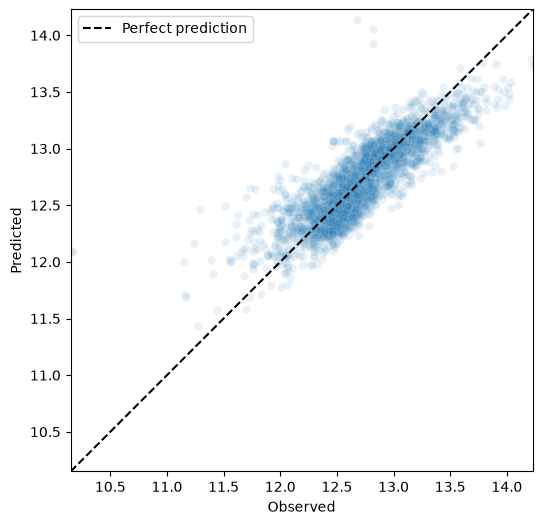

In [8]:
y_hat = X @ beta_hat # Make predictions

fig, ax = plt.subplots(figsize=(6, 6))
sns.scatterplot(x=y, y= y_hat, alpha=0.1, ax=ax)
lims = [
    min(np.min(y), np.min(y_hat)),
    max(np.max(y), np.max(y_hat))
]
ax.plot(lims, lims, 'k--', linewidth=1.5, label='Perfect prediction')
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_aspect('equal', adjustable='box')
ax.set_xlabel('Observed')
ax.set_ylabel('Predicted')
ax.legend()
plt.show()

In [9]:
R = 1_000
results = []
for t in range(R):
    idx = np.random.randint( 0 , len(rdf), len(rdf))
    beta_hat_t = mlr(X.iloc[idx], y.iloc[idx])
    results.append(beta_hat_t)
results = np.array(results)

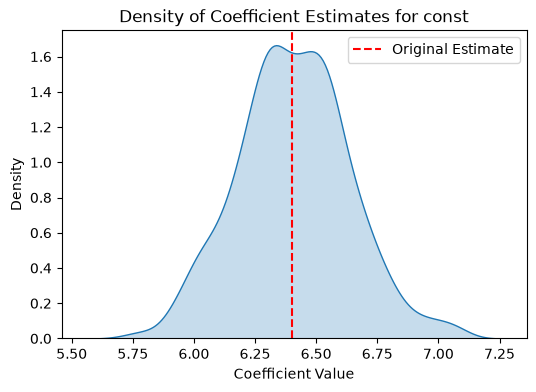

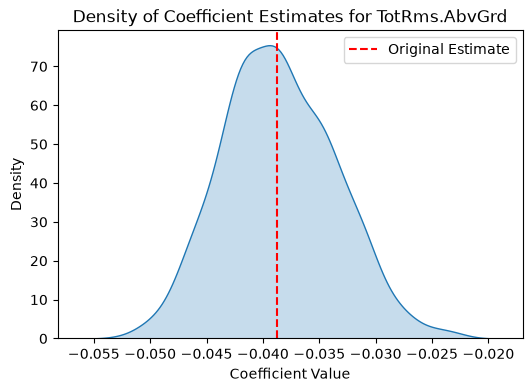

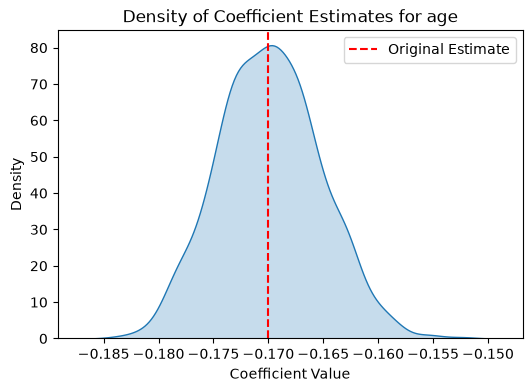

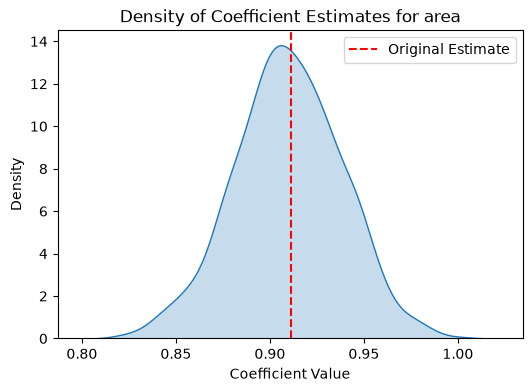

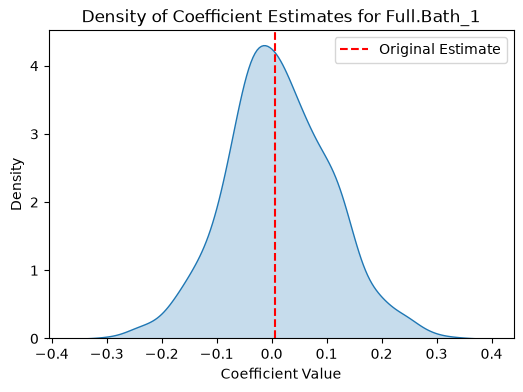

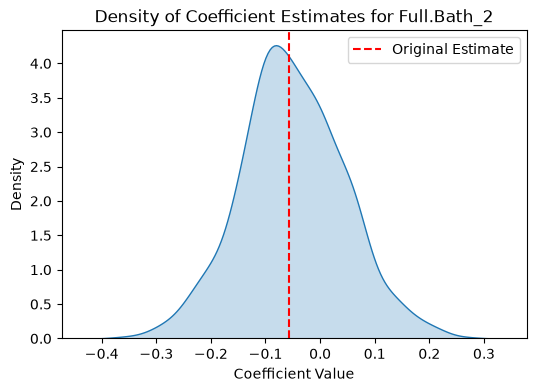

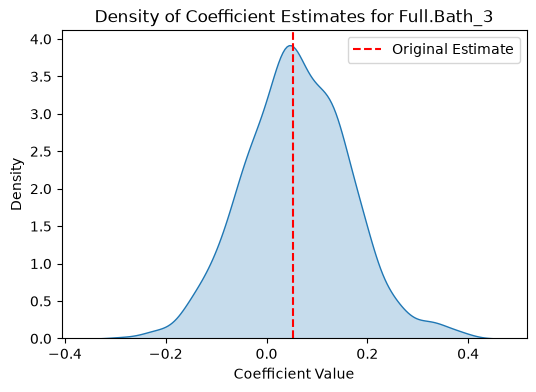

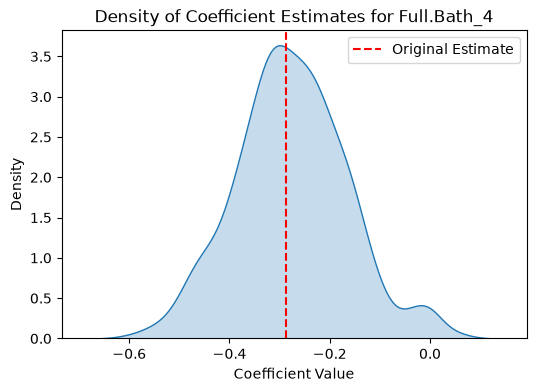

In [10]:
vars = X.columns.to_list()
for idx, var in enumerate(vars):
    plt.figure(figsize=(6, 4))
    sns.kdeplot(results[:, idx], fill=True)
    plt.axvline(beta_hat[idx], color='red', linestyle='--', label='Original Estimate')
    plt.title(f'Density of Coefficient Estimates for {var}')
    plt.xlabel('Coefficient Value')
    plt.ylabel('Density')
    plt.legend()
    plt.show()

## 2. Fitting the Bootstrapped Sampling Distribution

What if we overlayed a normal with the **bootstrap mean** 
$$
\bar{\beta}_{\text{boot}} = \frac{1}{R} \sum_{b=1}^R \hat{\beta}_b
$$
and the standard deviation of the bootstrap sample --- which is our estimate of the **standard error** ---
$$
\widehat{\text{SE}}(\hat{\beta})= \sqrt{ \frac{1}{R-1}\sum_{b=1}^R (\hat{\beta}_b-\bar{\beta}_{\text{boot}})^2}?
$$

90% Confidence Interval for const: [6.0210, 6.7859]
95% Confidence Interval for const: [5.9713, 6.8728]
99% Confidence Interval for const: [5.8762, 7.0494]


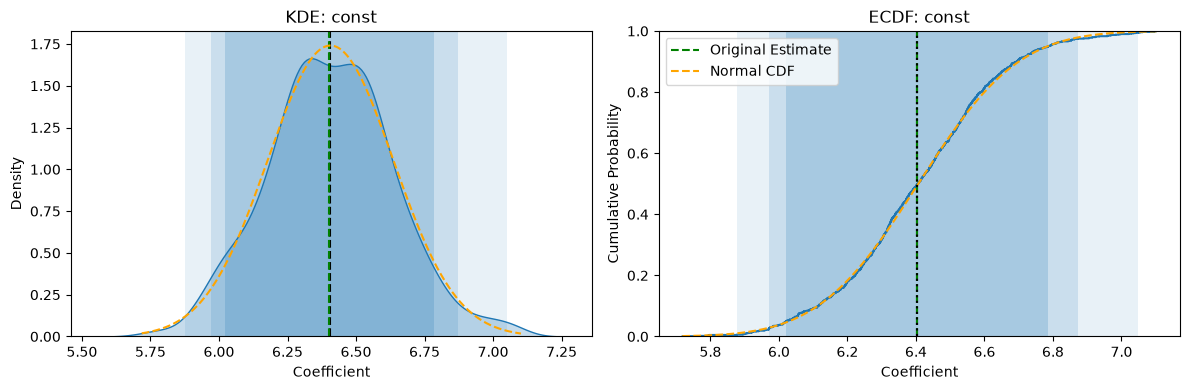

90% Confidence Interval for TotRms.AbvGrd: [-0.0466, -0.0302]
95% Confidence Interval for TotRms.AbvGrd: [-0.0478, -0.0285]
99% Confidence Interval for TotRms.AbvGrd: [-0.0502, -0.0246]


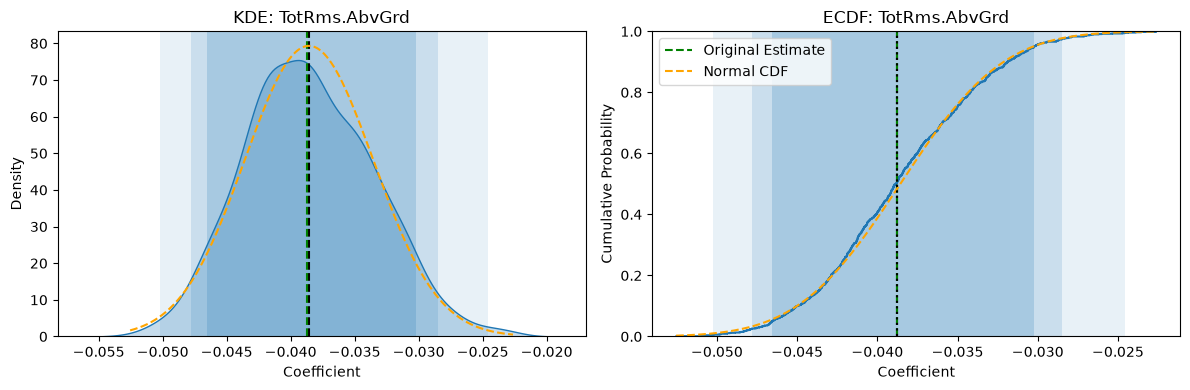

90% Confidence Interval for age: [-0.1776, -0.1623]
95% Confidence Interval for age: [-0.1786, -0.1607]
99% Confidence Interval for age: [-0.1807, -0.1581]


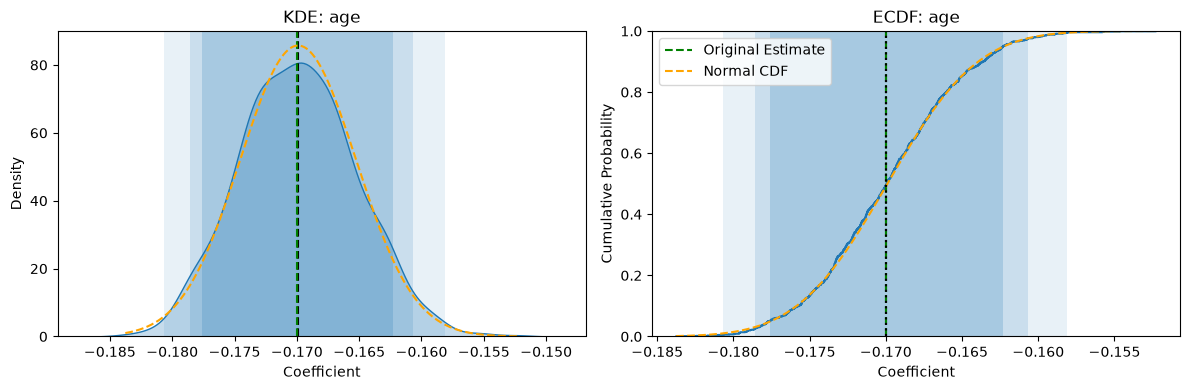

90% Confidence Interval for area: [0.8612, 0.9549]
95% Confidence Interval for area: [0.8509, 0.9640]
99% Confidence Interval for area: [0.8381, 0.9809]


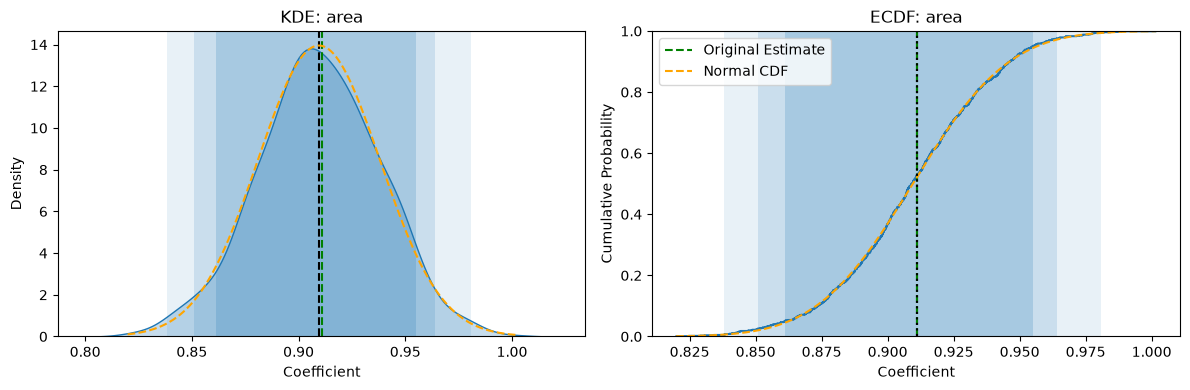

90% Confidence Interval for Full.Bath_1: [-0.1455, 0.1708]
95% Confidence Interval for Full.Bath_1: [-0.1760, 0.2050]
99% Confidence Interval for Full.Bath_1: [-0.2437, 0.2599]


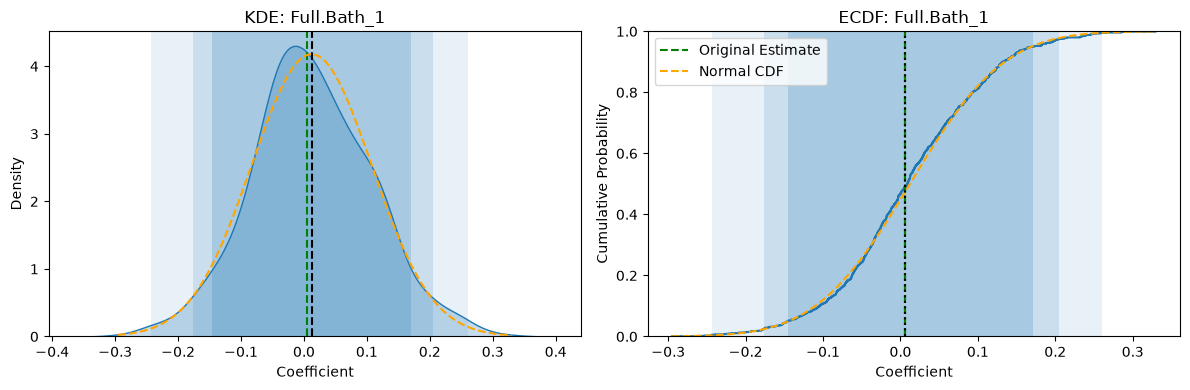

90% Confidence Interval for Full.Bath_2: [-0.2073, 0.1053]
95% Confidence Interval for Full.Bath_2: [-0.2396, 0.1439]
99% Confidence Interval for Full.Bath_2: [-0.2959, 0.2115]


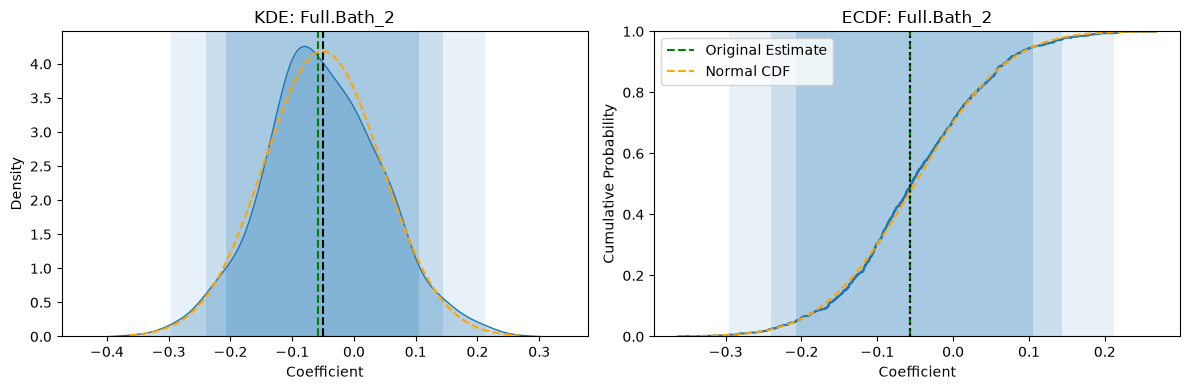

90% Confidence Interval for Full.Bath_3: [-0.1078, 0.2260]
95% Confidence Interval for Full.Bath_3: [-0.1402, 0.2645]
99% Confidence Interval for Full.Bath_3: [-0.2142, 0.3606]


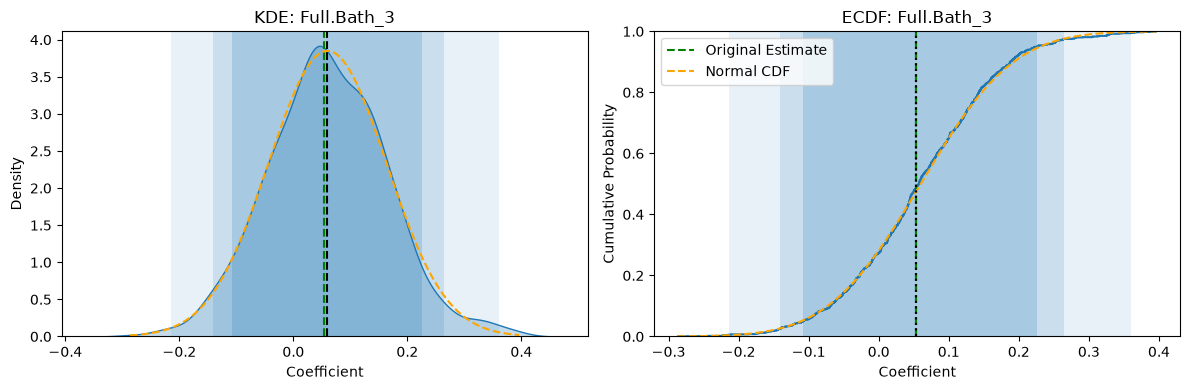

90% Confidence Interval for Full.Bath_4: [-0.4614, -0.0997]
95% Confidence Interval for Full.Bath_4: [-0.4881, -0.0286]
99% Confidence Interval for Full.Bath_4: [-0.5468, 0.0000]


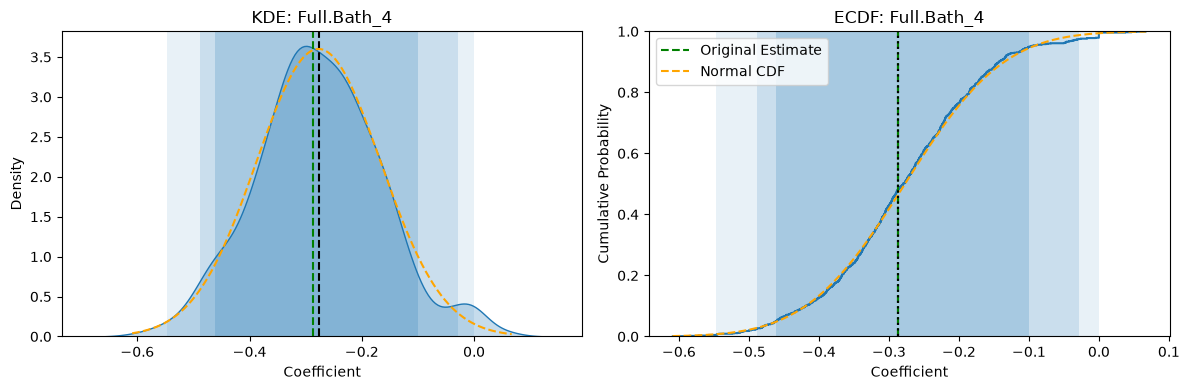

In [11]:
vars = X.columns.to_list()

for idx, var in enumerate(vars):
    sample = results[:, idx]
    mean = np.mean(sample)
    standard_error = np.std(sample, ddof=1)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))

    # KDE
    sns.kdeplot(sample, fill=True, ax=ax[0])
    ax[0].axvline(mean, color='black', linestyle='--')
    ax[0].set_title(f'KDE: {var}')
    ax[0].set_xlabel('Coefficient')
    ax[0].set_ylabel('Density')
    ax[0].axvline(beta_hat[idx], color='green', linestyle='--',
        label='Original Estimate')
    x_grid = np.linspace(sample.min(), sample.max(), 500)
    ax[0].plot(
        x_grid,
        norm.pdf(x_grid, loc=mean, scale=standard_error),
        color='orange',
        linestyle='--',
        label='Normal PDF'
    )
    
    # ECDF
    sns.ecdfplot(sample, ax=ax[1])
    ax[1].axvline(beta_hat[idx], color='black', linestyle='--')
    ax[1].set_title(f'ECDF: {var}')
    ax[1].set_xlabel('Coefficient')
    ax[1].set_ylabel('Cumulative Probability')
    ax[1].set_ylim(0, 1)
    ax[1].axvline(beta_hat[idx], color='green', linestyle='--',
        label='Original Estimate')
    # Fitted normal CDF
    x_grid = np.linspace(sample.min(), sample.max(), 500)
    ax[1].plot(
        x_grid,
        norm.cdf(x_grid, loc=mean, scale=standard_error),
        color='orange',
        linestyle='--',
        label='Normal CDF'
    )
    ax[1].axvline(beta_hat[idx], color='black', linestyle=':')
    ax[1].set_title(f'ECDF: {var}')
    ax[1].set_xlabel('Coefficient')
    ax[1].set_ylabel('Cumulative Probability')
    ax[1].set_ylim(0, 1)
    ax[1].legend()

    # Percentile bootstrap confidence intervals
    ci90 = np.quantile(sample, [.05, .95])
    ci95 = np.quantile(sample, [.025, .975])
    ci99 = np.quantile(sample, [.005, .995])

    ax[0].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
    ax[0].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
    ax[0].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")
    ax[1].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
    ax[1].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
    ax[1].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

    L = np.quantile(sample, .05)
    U = np.quantile(sample, .95)
    print(f'90% Confidence Interval for {var}: [{L:.4f}, {U:.4f}]')
    L = np.quantile(sample, .025)
    U = np.quantile(sample, .975)
    print(f'95% Confidence Interval for {var}: [{L:.4f}, {U:.4f}]')
    L = np.quantile(sample, .005)
    U = np.quantile(sample, .995)
    print(f'99% Confidence Interval for {var}: [{L:.4f}, {U:.4f}]')

    plt.tight_layout()
    plt.show()

## 3. $z$-Score Normalization
- Let's go a step further, and $z$-score normalize our estimates:
$$
Z_b = \dfrac{\hat{\beta}_b - \hat{\beta}}{\widehat{\text{SE}}(\hat{\beta})}
$$
- In short, how close is a Normal distribution with mean $\hat{\beta}$ and standard deviation $\widehat{\text{SE}}(\hat{\beta})$ to the bootstrapped estimate of the sampling distribution? Are the $Z_b$ values approximately standard normally distributed?
- Look at what happens to the confidence intervals, in particular

90% Confidence Interval for const: [-1.6652, 1.6716]
95% Confidence Interval for const: [-1.8821, 2.0508]
99% Confidence Interval for const: [-2.2968, 2.8214]


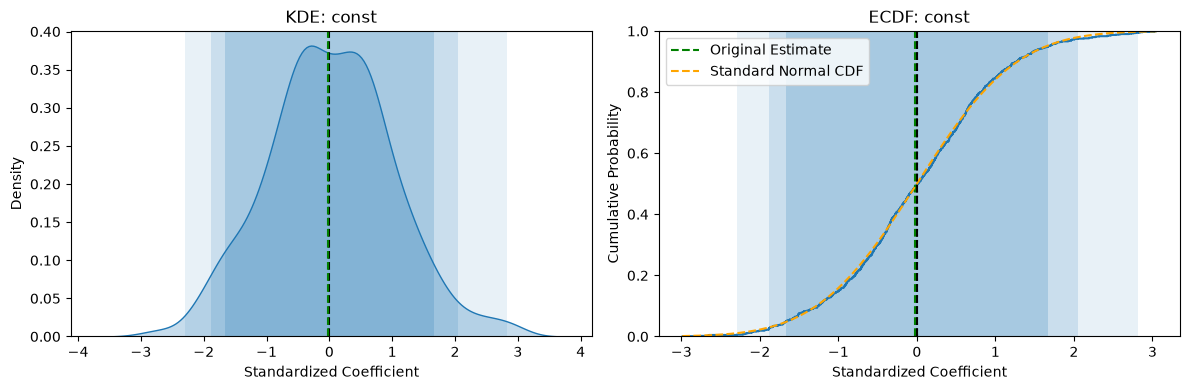

90% Confidence Interval for TotRms.AbvGrd: [-1.5521, 1.6954]
95% Confidence Interval for TotRms.AbvGrd: [-1.8017, 2.0418]
99% Confidence Interval for TotRms.AbvGrd: [-2.2810, 2.8209]


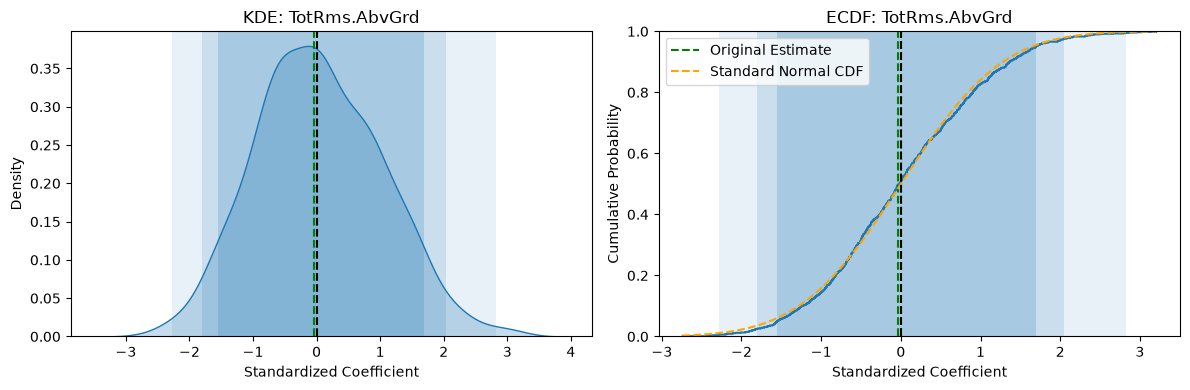

90% Confidence Interval for age: [-1.6384, 1.6529]
95% Confidence Interval for age: [-1.8446, 1.9999]
99% Confidence Interval for age: [-2.2905, 2.5543]


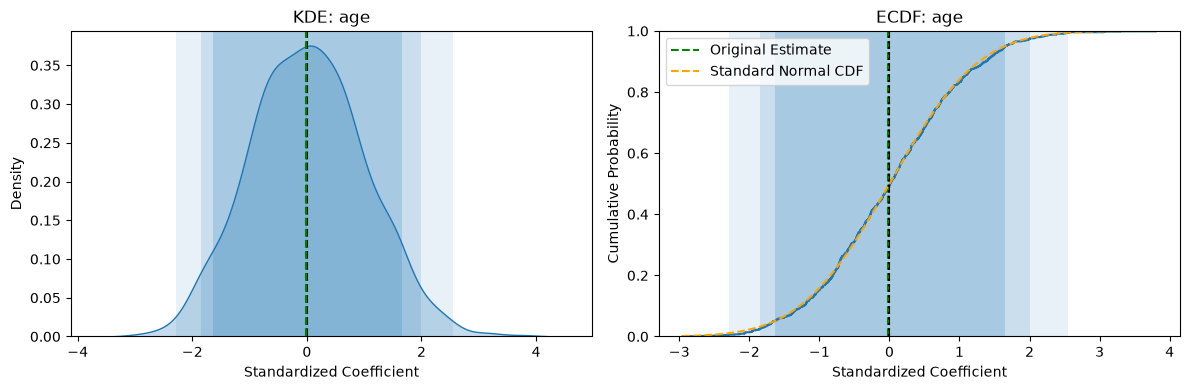

90% Confidence Interval for area: [-1.7449, 1.5329]
95% Confidence Interval for area: [-2.1070, 1.8496]
99% Confidence Interval for area: [-2.5519, 2.4413]


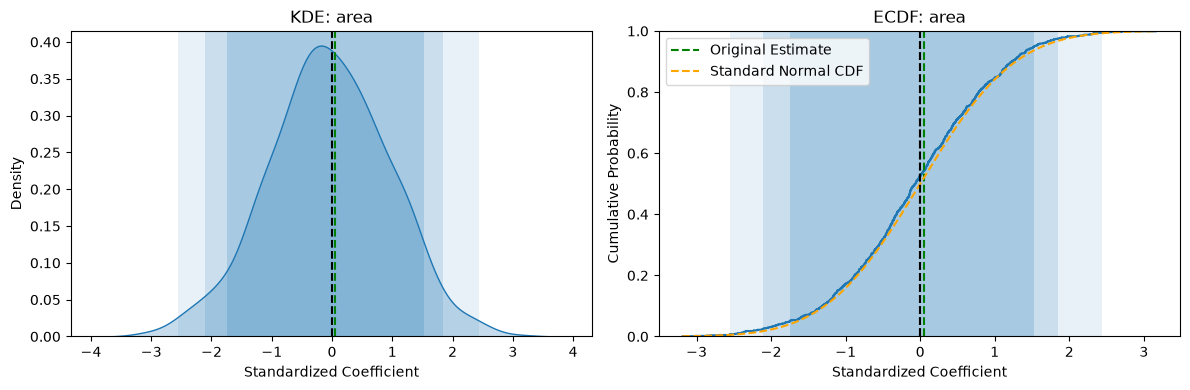

90% Confidence Interval for Full.Bath_1: [-1.5833, 1.7301]
95% Confidence Interval for Full.Bath_1: [-1.9027, 2.0881]
99% Confidence Interval for Full.Bath_1: [-2.6112, 2.6631]


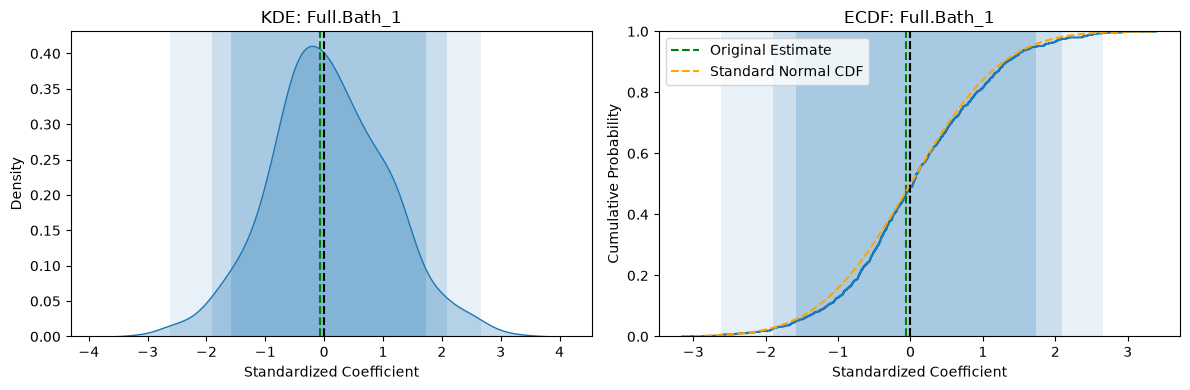

90% Confidence Interval for Full.Bath_2: [-1.5731, 1.7076]
95% Confidence Interval for Full.Bath_2: [-1.9122, 2.1127]
99% Confidence Interval for Full.Bath_2: [-2.5024, 2.8220]


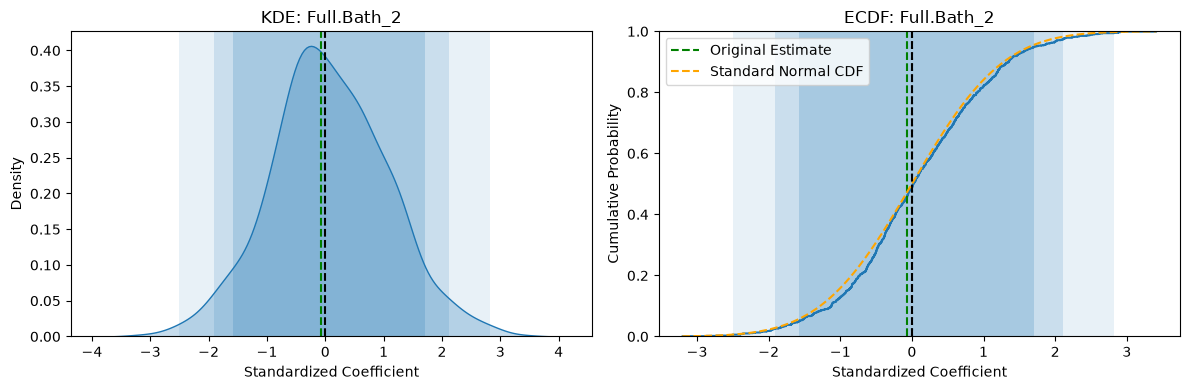

90% Confidence Interval for Full.Bath_3: [-1.5570, 1.6640]
95% Confidence Interval for Full.Bath_3: [-1.8691, 2.0364]
99% Confidence Interval for Full.Bath_3: [-2.5839, 2.9633]


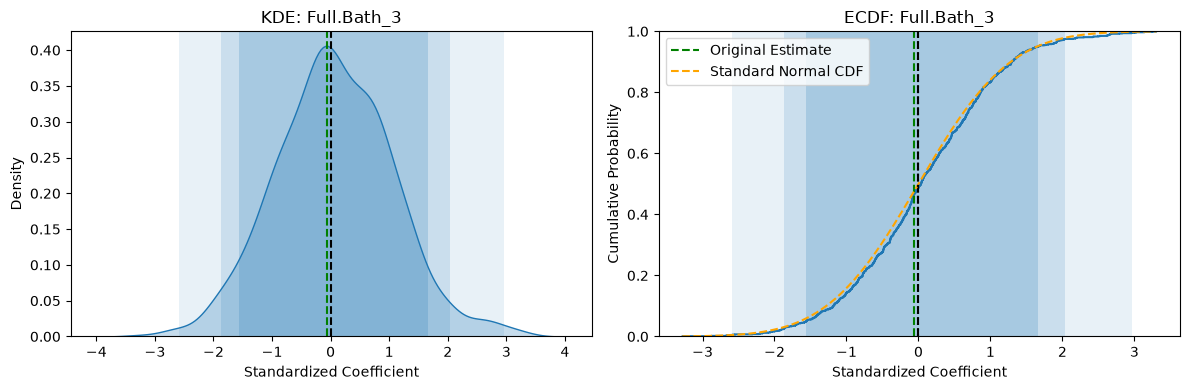

90% Confidence Interval for Full.Bath_4: [-1.5724, 1.6923]
95% Confidence Interval for Full.Bath_4: [-1.8136, 2.3336]
99% Confidence Interval for Full.Bath_4: [-2.3428, 2.5917]


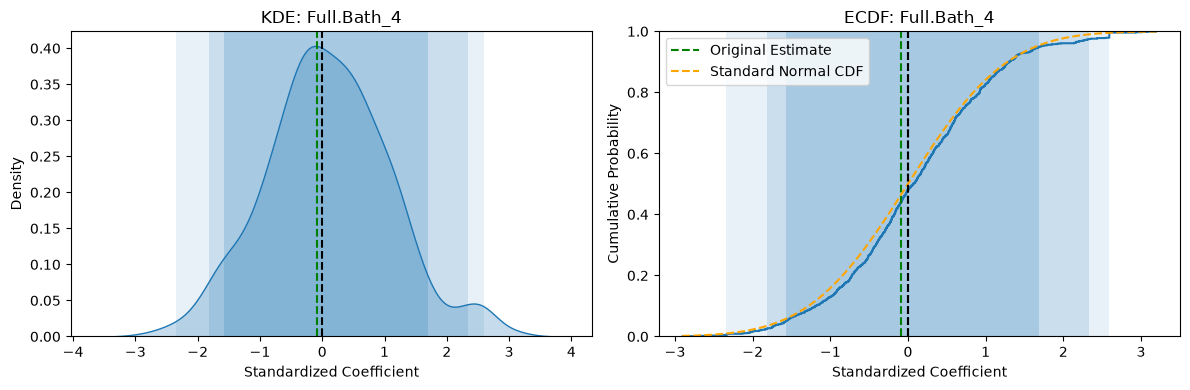

In [12]:
vars = X.columns.to_list()

for idx, var in enumerate(vars):
    sample = results[:, idx]
    mean = np.mean(sample)
    standard_error = np.std(sample, ddof=1)
    z = (sample - beta_hat[idx]) / standard_error
    z_original = (beta_hat[idx] - mean) / standard_error
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))

    # KDE
    sns.kdeplot(z, fill=True, ax=ax[0])
    ax[0].axvline(0, color='black', linestyle='--')
    ax[0].set_title(f'KDE: {var}')
    ax[0].set_xlabel('Standardized Coefficient')
    ax[0].set_ylabel('Density')
    ax[0].axvline(z_original, color='green', linestyle='--',
        label='Original Estimate')
    # ECDF
    sns.ecdfplot(z, ax=ax[1])
    ax[1].axvline(0, color='black', linestyle='--')
    ax[1].set_title(f'ECDF: {var}')
    ax[1].set_xlabel('Standardized Coefficient')
    ax[1].set_ylabel('Cumulative Probability')
    ax[1].set_ylim(0, 1)
    ax[1].axvline(z_original, color='green', linestyle='--',
        label='Original Estimate')
    # Fitted normal CDF
    x_grid = np.linspace(z.min(), z.max(), 500)
    ax[1].plot(
        x_grid,
        norm.cdf(x_grid),
        color='orange',
        linestyle='--',
        label='Standard Normal CDF'
    )

    ax[1].axvline(0, color='black', linestyle=':')
    ax[1].set_title(f'ECDF: {var}')
    ax[1].set_xlabel('Standardized Coefficient')
    ax[1].set_ylabel('Cumulative Probability')
    ax[1].set_ylim(0, 1)
    ax[1].legend()

    # Percentile bootstrap confidence intervals
    ci90 = np.quantile(z, [.05, .95])
    ci95 = np.quantile(z, [.025, .975])
    ci99 = np.quantile(z, [.005, .995])

    ax[0].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
    ax[0].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
    ax[0].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")
    ax[1].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
    ax[1].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
    ax[1].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

    L = np.quantile(z, .05)
    U = np.quantile(z, .95)
    print(f'90% Confidence Interval for {var}: [{L:.4f}, {U:.4f}]')
    L = np.quantile(z, .025)
    U = np.quantile(z, .975)
    print(f'95% Confidence Interval for {var}: [{L:.4f}, {U:.4f}]')
    L = np.quantile(z, .005)
    U = np.quantile(z, .995)
    print(f'99% Confidence Interval for {var}: [{L:.4f}, {U:.4f}]')

    plt.tight_layout()
    plt.show()

## But Wait
- After $z$-score normalizing, we got roughly the same picture, over and over
- If we get basically the same picture every time, and the bootstrap ECDF and the standard Normal align almost perfectly, then can't we just approximate the sampling distribution of $Z$-scores by a standard Normal?
- This is the basic logic behind classical asymptotic inferential statistics: If the $z$-score normalized densities of "most things" appear to follow the bell curve, let's just use the bell curve to construct CIs and conduct hypothesis tests?

99% interval: [-2.5758, 2.5758]
95% interval: [-1.9600, 1.9600]
90% interval: [-1.6449, 1.6449]


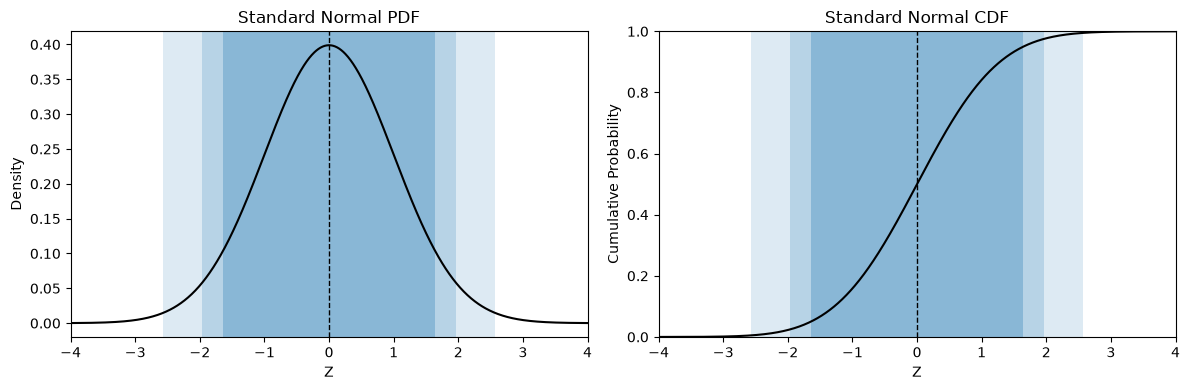

In [13]:
x = np.linspace(-4, 4, 1000)
pdf = norm.pdf(x)
cdf = norm.cdf(x)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# Standard normal PDF and CDF
ax[0].plot(x, pdf, color='black', linewidth=1.5)
ax[1].plot(x, cdf, color='black', linewidth=1.5)

# Nested confidence regions: largest first
for confidence, alpha in [(0.99, 0.15),
                          (0.95, 0.20),
                          (0.90, 0.30)]:

    z = norm.ppf((1 + confidence) / 2)
    mask = np.abs(x) <= z
    ax[0].axvspan(-z, z, alpha=alpha)
    # Shade central interval under CDF
    ax[1].axvspan(-z, z, alpha=alpha)
    print(f'{confidence:.0%} interval: [{-z:.4f}, {z:.4f}]')

# Reference at zero
for a in ax:
    a.axvline(0, color='black', linestyle='--', linewidth=1)
    a.set_xlim(-4, 4)

ax[0].set_title('Standard Normal PDF')
ax[0].set_xlabel('Z')
ax[0].set_ylabel('Density')

ax[1].set_title('Standard Normal CDF')
ax[1].set_xlabel('Z')
ax[1].set_ylabel('Cumulative Probability')
ax[1].set_ylim(0, 1)

plt.tight_layout()
plt.show()

## The Central Limit Theorem
- Why is this happening?
- **Central Limit Theorem**: Let $[X_1, X_2, ..., X_N]$ be a sample of IID random variables, each with mean $\mu$ and variance $\sigma^2$. Then for the sample mean $\bar{X}_n = \sum_{i=1}^N x_i/N$, as $N$ goes to infinity, 
$$
\frac{\bar{X}_n - \mu}{\sigma/\sqrt{n}} \rightarrow N(0,1)
$$
- This is what we observed above: For a big enough sample, that quantity is roughly normal
- We replace $\bar{X}_n$ by our parameter estimate, and $\sigma/\sqrt{n}$ by the Standard Error of the parameter or the Standard Deviation of the Sampling Distribution (do not divide by $\sqrt{n}$ again, it's baked into the bootstrap estimate)
- For many of the quantities we study, there is a sum of IID random variables happening somewhere, to which the CLT applies
- You can spend your adult life studying this and adjacent ideas

## Perhaps Memorize These

- Instead of taking the quantiles of our bootstrap sample, we can take the quantiles of the standard Normal distribution, then invert the $z$-score normalization to get our confident intervals:

| Confidence | Lower bound | Upper bound | Level ($\alpha$) |
|---|---:|---:| ---:|
| 90% | −1.645 | +1.645 | .10 |
| 95% | −1.960 | +1.960 | .05 |
| 99% | −2.576 | +2.576 | .01 |

So the 90% CI interval comes from this bound:
$$
\left| \frac{\beta_0 - \hat{\beta}}{\widehat{\text{SE}}(\hat{\beta})} \right| \le 1.645
$$
or
$$
\hat{\beta} - 1.645 \times \widehat{\text{SE}}(\hat{\beta}) \le \beta_0 \le \hat{\beta} + 1.645 \times \widehat{\text{SE}}(\hat{\beta})
$$

## Constructing Confidence Intervals
- 90% CI:
$$
( \hat{\beta} - 1.645 \times \widehat{\text{SE}}(\hat{\beta}) \quad , \quad \hat{\beta} + 1.645 \times \widehat{\text{SE}}(\hat{\beta}) )
$$
- 95% CI:
$$
( \hat{\beta} - 1.960 \times \widehat{\text{SE}}(\hat{\beta}) \quad , \quad \hat{\beta} + 1.960 \times \widehat{\text{SE}}(\hat{\beta}) )
$$
- 99% CI:
$$
( \hat{\beta} - 2.576 \times \widehat{\text{SE}}(\hat{\beta}) \quad , \quad \hat{\beta} + 2.576 \times \widehat{\text{SE}}(\hat{\beta}) )
$$

## Connection with Hypothesis Testing
- We define the **null hypothesis**
$$
H_0 : \beta_0 = z
$$
and the **alternative hypothesis**
$$
H_A : \beta_0 \neq z
$$
and specify a **confidence level**, typically .90/.95/.99.

- If $z$ is in the confidence interval, we fail to reject the null; otherwise, we reject the null.
- The value $z$ is very often zero, and we're testing the hypothesis that the parameter takes the value 0.
- We often "secretly want" to reject the null, finding evidence in the favor of the alternative, that the true value of the parameter is not 0

## Example
- You run a regression, and get a coefficient of $5$ with a standard error of $2$ for a key coefficient
- Then the 90% CI is $( 5 - 1.645 \times 2, 5 + 1.645 \times 2) = (1.71, 8.29)$
- Then the 95% CI is $( 5 - 1.960 \times 2, 5 + 1.960 \times 2) = (1.08, 8.92)$
- Then the 99% CI is $( 5 - 2.576 \times 2, 5 + 2.576 \times 2) = (-.15, 10.15)$
- For which levels of confidence is a statistically significant difference from 0 detected?

## Exercise

- You run a regression, and get a coefficient of $10$ with a standard error of $5$ for a key coefficient
- Compute 90/95/99% confidence intervals for the coefficient
- For which levels of confidence is a statistically significant difference from 0 detected?

## What is a Confidence Interval?
- Suppose our estimator is approximately normally distributed:
$$
\frac{\hat{\beta} - \beta_0}{\widehat{\text{SE}}(\hat{\beta})} \sim N(0,1)
$$
- Choose a **critical value** $c$ such that:
$$
\text{pr}\left[ \left| \dfrac{\hat{\beta}-\beta_0}{\widehat{\text{SE}}(\hat{\beta})} \right| \le c \right] = 1 - \alpha
$$
- What is random? $\hat{\beta}$ is a random function of the data. What is fixed? The unknown parameter $\beta_0$ is fixed. This is very, very confusing. The intervals are random functions of data, the parameter is fixed.
- Rearrange to get:
$$
\text{pr}_{\hat{\beta}}\left[ \hat{\beta} - c \times \widehat{\text{SE}}(\hat{\beta}) \le \beta_0 \le \hat{\beta} + c \times \widehat{\text{SE}}(\hat{\beta}) \right] = 1 - \alpha
$$
- This is a statistical reliability claim, not a probability assigned to the unknown parameter value, $\beta_0$

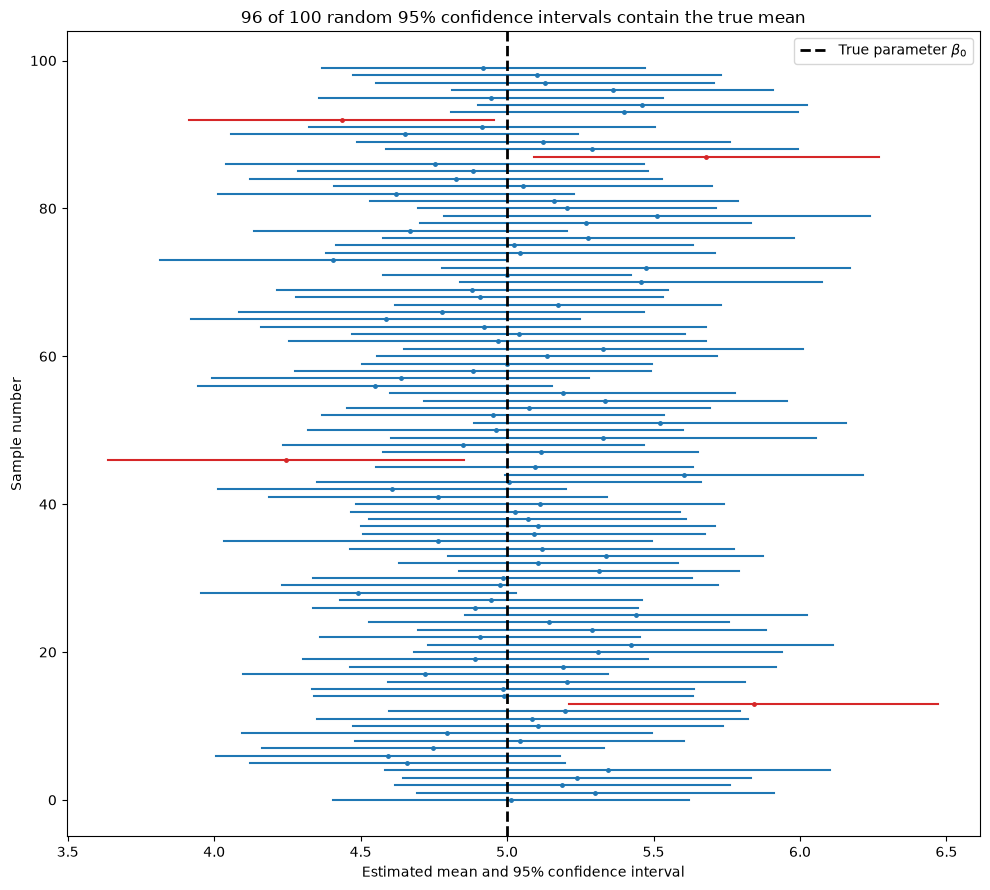

Coverage: 96.0%


In [14]:
rng = np.random.default_rng(100)

# Population and sampling parameters
beta_0 = 5.0             # True population mean (fixed!)
sigma = 2.0              # Population standard deviation
n = 40                   # Observations per sample
R = 100                  # Number of independent samples
c = 1.96                 # 95% confidence interval

# Generate R independent samples
X = rng.normal(beta_0, sigma, size=(R, n))

# Estimate the mean and its standard error for each sample
beta_hat = X.mean(axis=1)
se_hat = X.std(axis=1, ddof=1) / np.sqrt(n)

# Construct confidence intervals
lower = beta_hat - c * se_hat
upper = beta_hat + c * se_hat

# Which intervals contain the true parameter?
covers = (lower <= beta_0) & (beta_0 <= upper)

# Plot
fig, ax = plt.subplots(figsize=(10, 9))

for i in range(R):
    color = 'tab:blue' if covers[i] else 'tab:red'
    ax.plot([lower[i], upper[i]], [i, i], color=color, lw=1.5)
    ax.plot(beta_hat[i], i, '.', color=color, markersize=5)

ax.axvline(beta_0, color='black', linestyle='--',
           linewidth=2, label=r'True parameter $\beta_0$')

ax.set_xlabel(r'Estimated mean and 95% confidence interval')
ax.set_ylabel('Sample number')
ax.set_title(f'{covers.sum()} of {R} random 95% confidence intervals contain the true mean')
ax.legend()
plt.tight_layout()
plt.show()

print(f"Coverage: {covers.mean():.1%}")

## CI to Hypothesis Test
- If we hypothesize $\beta_0$ to take some value $z$, this becomes a **hypothesis test**: Is the hypothesized value $z$ in the interval or not?
$$
\text{pr}_{\hat{\beta}, \text{ when } \beta_0 = z}\left[ \hat{\beta} - c \times \text{SE}(\hat{\beta}) \le z \le \hat{\beta} + c \times \text{SE}(\hat{\beta}) \right] \approx 1 - \alpha
$$
- This is the abstract version of our question: Is $z$ (often 0) outside the CI? If so, reject $H_0$; if it is inside the CI, fail to reject $H_0$.
- If $z$ really were the parameter value, this procedure would exclude it about 10/5/1% of the time for a 90/95/99% confidence interval (this is what **confidence** is)

## The CI is not...
- This is just not $\text{pr}_{\beta_0}[ |\hat{\beta}-\beta_0| \le c ]$ --- The parameter $\beta_0$ is fixed but unknown, not random
- If $\beta_0$ was random, and had a distribution associated with it, then you'd use Bayes' Rule to observe data and update that distribution
- We often say things like, "Gravity is $-9.81 m/s^2$". We don't often say things like, "Gravity is normally distributed with mean $-9.81 m/s^2$ and standard deviation $.0051$"
- If you **did** talk like that, you'd be a Bayesian Statistician, and we'll talk about Bayesian Statistics at the end of the course

## The CI is...
- A set of parameter values that our data do not allow us to reject, using a procedure designed to exclude the true parameter only a specified fraction of the time (the Type 1 error probability).
- Given our observed estimate and its uncertainty, which hypothetical values of the true parameter could we reasonably rule out? (probabilistic reductio ad absurdum: given the hypothesis, what's the probability of observing data that give results at least as extreme as those we got?)
- If we repeatedly sampled data and constructed a new confidence interval each time, approximately 90/95/99% of those intervals would contain the fixed, unknown parameter $\beta_0$ (the bootstrapping connection is the literal repeated sampling)

## Standard Errors
- The **standard error is the standard deviation of the sampling distribution**. These are important but difficult to understand, because the data and estimator create the standard error
- It often shows up in formulas as "$\sigma/\sqrt{n}$", but that can be somewhat confusing: The standard error is always the standard deviation of the sampling distribution, whatever that is (sometimes it's $\sigma/\sqrt{n}$ or $p(1-p)/\sqrt{n}$ or whatever: It depends on the estimator)
- In these notes, we're using the standard deviation of the bootstrap sample as an estimate of the standard error of the sampling distribution,
$$
\widehat{\text{SE}}(\hat{\beta}) = \sqrt{ \frac{1}{R-1}\sum_{b=1}^R (\hat{\beta}_b-\bar{\beta}_{\text{boot}})^2}
$$
and doing the standard $Z$/Normal-version of bootstrapping
$$
Z_b = \frac{\hat{\beta}_b - \hat{\beta}}{\widehat{\text{SE}}(\hat{\beta})}
$$

## Exercise

- Load the Metabric breast cancer dataset, and describe/plot `Overall Survival (Months)`.
- Describe a strategy for selecting variables that you'll use to predict `Overall Survival (Months)`, then implement your strategy and run your regression.
- Construct 90/95/99% non-parametric Bootstrap confidence intervals for the coefficients of your regression, as well as ones based on the Normal approximation using the standard deviation of the bootstrap sample as the standard error of the sampling distribution. How do they compare?
- Which variables are statistically significant, and at what levels?

Let's just plot the histogram and ecdf to start. Note that if the person is still living when this data was collected, overall survival is just counts months until the end of the data collection (in other words, censored data. There is a hard cutoff of end date.)

(1343, 14)
count    1343.000000
mean      129.094291
std        78.290236
min         0.100000
25%        62.700000
50%       118.533333
75%       191.200000
max       351.000000
Name: Overall Survival (Months), dtype: float64
Overall Survival Status
1:DECEASED    768
0:LIVING      575
Name: count, dtype: int64


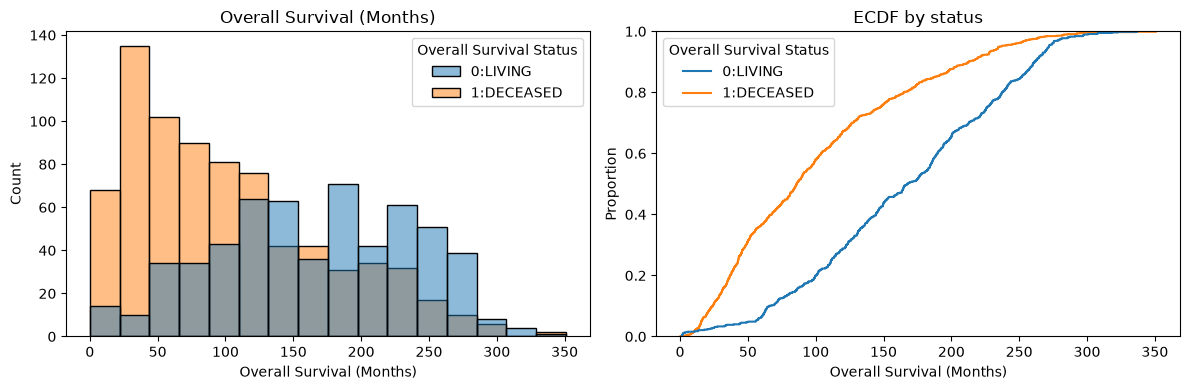

In [15]:
df = pd.read_csv('./data/metabric.csv')
print(df.shape)
print(df['Overall Survival (Months)'].describe())
print(df['Overall Survival Status'].value_counts())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df, x='Overall Survival (Months)', hue='Overall Survival Status', ax=ax[0])
ax[0].set_title('Overall Survival (Months)')
sns.ecdfplot(data=df, x='Overall Survival (Months)', hue='Overall Survival Status', ax=ax[1])
ax[1].set_title('ECDF by status')
plt.tight_layout()
plt.show()

### Variable selection
- Strategy: pick variables a doctor would use
- Numeric: `Age at Diagnosis`; `Tumor Size` and `Lymph nodes examined positive` are right-skewed, so use the arcsinh transform like we did for Ames
- Treatments as 0/1 dummies: `Chemotherapy`, `Hormone Therapy`, `Radio Therapy`, `Type of Breast Surgery`
- Leave out `Nottingham prognostic index` (it is built from tumor size, grade, and lymph nodes, so it duplicates them) and `Cancer Type` (only one value)
- Leave out `Tumor Stage` as dummies: stages 0 and 4 have only 2 and 7 patients, so their bootstrap distributions would be lumpy
- Use new names (`mX`, `my`, ...) so the Ames variables above are not overwritten

In [16]:
outcome_var = ['Overall Survival (Months)']
num_vars = ['Age at Diagnosis', ]
num_ihs_vars = ['Tumor Size',
                'Lymph nodes examined positive', ]
cat_vars = ['Chemotherapy',
            'Hormone Therapy',
            'Radio Therapy',
            'Type of Breast Surgery', ]

mrdf = df.loc[:, outcome_var + num_vars + num_ihs_vars + cat_vars].dropna()

mX = mrdf.loc[:, num_vars]
for var in num_ihs_vars:
    mX = pd.concat([mX, np.arcsinh(mrdf[var])], axis=1)
for var in cat_vars:
    mX = pd.concat([mX, pd.get_dummies(mrdf[var], dtype=int, drop_first=True, prefix=var)], axis=1)

### Add intercept:
mX.insert(0, 'const', 1.0)
my = mrdf['Overall Survival (Months)']

m_beta_hat = mlr(mX, my)
print(pd.Series(m_beta_hat, index=mX.columns).round(3))

const                                288.074
Age at Diagnosis                      -1.240
Tumor Size                           -18.089
Lymph nodes examined positive        -13.620
Chemotherapy_YES                     -32.498
Hormone Therapy_YES                   -4.861
Radio Therapy_YES                      5.582
Type of Breast Surgery_MASTECTOMY      3.710
dtype: float64


### Bootstrap the coefficients
- Same loop as for Ames: resample whole rows, refit, save the coefficients

In [17]:
np.random.seed(5030)
R = 1_000
m_results = []
for t in range(R):
    # a few different ways to bootstrap that you've seen in class so far. 
    # If you are sampling rows from a df, you can use the built-in pandas method sample() with replace=True,
    #  or you can use numpy's random.choice() or random.randint() to generate indices. 
    # Here, we use np.random.randint() to generate random indices for bootstrapping. 
    # Notice the seed is set once at the top of the loop, 
    # so that the results are reproducible AND each resample is different.
    idx = np.random.randint(0, len(mrdf), len(mrdf))
    m_results.append(mlr(mX.iloc[idx], my.iloc[idx]))
m_results = np.array(m_results)

### Bootstrap vs. Normal-approximation CIs, and significance
- Bootstrap CI: quantiles of the bootstrap coefficients
- Normal CI: estimate $\pm$ critical value $\times$ SE, where SE is the SD of the bootstrap coefficients
- Test $H_0: \beta = 0$ with $z = \hat{\beta}/\widehat{\text{SE}}$ and two-sided $p = 2\Phi(-|z|)$; significant at a level when $p < \alpha$

In [18]:
rows = []
for idx, var in enumerate(mX.columns):
    sample = m_results[:, idx]
    se = np.std(sample, ddof=1)
    z = m_beta_hat[idx] / se            # H0: beta = 0
    p = 2 * norm.cdf(-np.abs(z))        # two-sided p-value
    row = {'variable': var, 'estimate': m_beta_hat[idx], 'SE': se, 'z': z, 'p': p}
    for conf, alpha in [(90, .10), (95, .05), (99, .01)]:
        c = norm.ppf(1 - alpha / 2)
        lo_b, hi_b = np.quantile(sample, [alpha / 2, 1 - alpha / 2])
        row[f'boot {conf}%'] = f'({lo_b:.2f}, {hi_b:.2f})'
        row[f'normal {conf}%'] = f'({m_beta_hat[idx] - c*se:.2f}, {m_beta_hat[idx] + c*se:.2f})'
    row['significant at'] = ', '.join(f'{conf}%' for conf, alpha in [(90, .10), (95, .05), (99, .01)] if p < alpha) or 'none'
    rows.append(row)

ci_table = pd.DataFrame(rows).set_index('variable')
ci_table.round(3)

,estimate,SE,z,p,boot 90%,normal 90%,boot 95%,normal 95%,boot 99%,normal 99%,significant at
variable,,,,,,,,,,,
const,288.074,18.537,15.541,0.000,"(260.75, 319.08)","(257.58, 318.56)","(254.47, 324.26)","(251.74, 324.41)","(238.38, 339.34)","(240.33, 335.82)","90%, 95%, 99%"
Age at Diagnosis,-1.240,0.187,-6.640,0.000,"(-1.56, -0.94)","(-1.55, -0.93)","(-1.61, -0.89)","(-1.61, -0.87)","(-1.74, -0.77)","(-1.72, -0.76)","90%, 95%, 99%"
Tumor Size,-18.089,4.390,-4.121,0.000,"(-25.15, -11.12)","(-25.31, -10.87)","(-26.86, -9.76)","(-26.69, -9.48)","(-30.60, -7.20)","(-29.40, -6.78)","90%, 95%, 99%"
Lymph nodes examined positive,-13.620,2.264,-6.016,0.000,"(-17.28, -9.61)","(-17.34, -9.90)","(-17.84, -8.86)","(-18.06, -9.18)","(-18.81, -7.92)","(-19.45, -7.79)","90%, 95%, 99%"
Chemotherapy_YES,-32.498,6.296,-5.162,0.000,"(-43.43, -22.11)","(-42.85, -22.14)","(-45.11, -20.66)","(-44.84, -20.16)","(-48.17, -17.13)","(-48.72, -16.28)","90%, 95%, 99%"
Hormone Therapy_YES,-4.861,4.533,-1.072,0.284,"(-12.28, 2.48)","(-12.32, 2.60)","(-14.15, 3.64)","(-13.75, 4.02)","(-17.02, 6.22)","(-16.54, 6.82)",none
Radio Therapy_YES,5.582,5.172,1.079,0.280,"(-3.02, 13.98)","(-2.93, 14.09)","(-4.99, 15.34)","(-4.56, 15.72)","(-7.87, 18.62)","(-7.74, 18.91)",none
Type of Breast Surgery_MASTECTOMY,3.710,5.323,0.697,0.486,"(-4.47, 12.73)","(-5.04, 12.47)","(-6.12, 14.10)","(-6.72, 14.14)","(-11.21, 18.26)","(-10.00, 17.42)",none


### Things to notice
- The bootstrap and Normal CIs are close for every coefficient: with 1,343 patients, the CLT picture holds
- Age, tumor size, positive lymph nodes, and chemotherapy are significant at all three levels; hormone therapy, radiotherapy, and surgery type are not significant at any level
- **Chemotherapy has a large *negative* coefficient.** That does not mean chemo shortens survival: doctors give chemo to patients with more aggressive cancer. The coefficient is an association, not a causal effect
- **Censoring:** `LIVING` patients' months are follow-up times, not survival times, so OLS on raw months understates survival. A survival model (Kaplan–Meier, Cox) handles this properly

## Five Things to Think About

1. The parameter is fixed but unknown. We're trying to learn something about a property of the population.
2. Our estimates/confidence intervals are random variables of the data. Different samples produce different estimates, even for the same population doesn't change.
3. The standard error measures variability in our estimators, and botstrapping gives us a practical way to estimate it.
4. The confidence interval translates variability into uncertainty about the parameter. Under the Normal approximation, that's $(\hat{\beta}\pm c \times \widehat{\mathrm{SE}})$. A hypothesized value outside the corresponding interval is rejected as implausible give the data and estimator.
5. The Bootstrap and the CLT are different approaches to understanding the underlying sampling distribution and making inferences about it, with their own strengths and weaknesses.